In [1]:
%pip install -q PyWavelets

Note: you may need to restart the kernel to use updated packages.


## 사전실험 B-1 전체 프레임의 주파수 변화 분석
### 압축하면 어떤 주파수 대역이 얼마나 변하는가

In [2]:

from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import pywt
import matplotlib.pyplot as plt

# ============================================================
# 1. 설정
# ============================================================

ROOT = Path("/kaggle/input/notebooks/naeunku")

REF_ROOT = ROOT / "uvg-build-dataset/uvg_cctv"
ENC_ROOT = ROOT / "uvg-eval3-gop60/cctv_gop60"

OUT = Path("/kaggle/working/B1_results")
OUT.mkdir(parents=True, exist_ok=True)

SEQUENCES = [
    "HighwayView",
    "CampusView",
    "JobFair",
    "VolleyballGame",
    "FloorballGame",
    "FloorballTrain"
]

RATES = [4000, 2000, 1000, 500, 250, 125]
FRAME_STEP = 5
EPS = 1e-12

U, V = np.meshgrid(np.arange(8), np.arange(8))
DCT_INDEX = U + V

DCT_GROUPS = {
    "DC": [0],
    "Low": [1, 2],
    "Mid": [3, 4, 5, 6],
    "High": list(range(7, 15))
}

WAVELET_NAMES = [
    "LL2", "LH2", "HL2", "HH2",
    "LH1", "HL1", "HH1"
]

# ============================================================
# 2. 올바른 DCT-II 직교정규 변환 행렬
# ============================================================

def make_dct_matrix(n=8):
    x = np.arange(n)
    k = np.arange(n)[:, None]

    T = np.cos(
        np.pi * (2 * x + 1) * k / (2 * n)
    )

    T[0, :] *= np.sqrt(1 / n)
    T[1:, :] *= np.sqrt(2 / n)

    return T.astype(np.float32)

DCT_MATRIX = make_dct_matrix(8)

# DCT 검증: cv2.dct 결과와 일치해야 함
test_block = np.arange(64, dtype=np.float32).reshape(8, 8)

manual_dct = DCT_MATRIX @ test_block @ DCT_MATRIX.T
opencv_dct = cv2.dct(test_block)

assert np.allclose(
    manual_dct,
    opencv_dct,
    atol=1e-4
), "DCT implementation verification failed"

print("DCT verification passed")

# ============================================================
# 3. 영상 Y 채널 추출
# ============================================================

def get_frame_count(path):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise FileNotFoundError(path)

    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    return n


def frames_y(path, selected):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise FileNotFoundError(path)

    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if selected and max(selected) >= n:
        cap.release()
        raise ValueError(f"Frame count mismatch: {path}")

    result = {}
    selected_set = set(selected)

    for idx in range(max(selected) + 1 if selected else 0):
        ok, frame = cap.read()

        if not ok:
            cap.release()
            raise RuntimeError(
                f"Cannot decode frame {idx}: {path}"
            )

        if idx in selected_set:
            y = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2YCrCb
            )[:, :, 0].astype(np.float32)

            result[idx] = y

    cap.release()

    return result, n

# ============================================================
# 4. 8x8 DCT
# ============================================================

def dct_coefficients(y):
    h, w = y.shape

    if h % 8 != 0 or w % 8 != 0:
        raise ValueError("Image dimensions must be divisible by 8")

    blocks = (
        np.ascontiguousarray(y)
        .reshape(h // 8, 8, w // 8, 8)
        .transpose(0, 2, 1, 3)
    )

    coeff = np.einsum(
        "au,ijuv,bv->ijab",
        DCT_MATRIX,
        blocks,
        DCT_MATRIX,
        optimize=True
    )

    return coeff

# ============================================================
# 5. 2-level Haar Wavelet
# ============================================================

def wavelet_coefficients(y):
    ll2, (lh2, hl2, hh2), (lh1, hl1, hh1) = (
        pywt.wavedec2(
            y,
            wavelet="haar",
            level=2,
            mode="periodization"
        )
    )

    return dict(
        zip(
            WAVELET_NAMES,
            [ll2, lh2, hl2, hh2, lh1, hl1, hh1]
        )
    )

# ============================================================
# 6. 주파수 손실 지표
# ============================================================

def measures(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    ref_energy = float(np.sum(a ** 2))
    cmp_energy = float(np.sum(b ** 2))
    error_energy = float(np.sum((a - b) ** 2))

    energy_ratio = (
        cmp_energy / ref_energy
        if ref_energy > EPS else np.nan
    )

    normalized_error = (
        error_energy / ref_energy
        if ref_energy > EPS else np.nan
    )

    return {
        "ref_energy": ref_energy,
        "cmp_energy": cmp_energy,
        "error_energy": error_energy,
        "n_coeff": a.size,
        "energy_ratio": energy_ratio,
        "normalized_error": normalized_error,
        "mse": error_energy / a.size
    }

# ============================================================
# 7. 프레임 분석
# ============================================================

def analyze_frame(ref_y, cmp_y, seq, bitrate, frame_idx):
    if ref_y.shape != cmp_y.shape:
        raise ValueError("Reference/compressed shape mismatch")

    rows = []

    rd = dct_coefficients(ref_y)
    cd = dct_coefficients(cmp_y)

    # DCT 15개 그룹
    for k in range(15):
        mask = DCT_INDEX == k

        rows.append({
            "sequence": seq,
            "bitrate_kbps": bitrate,
            "frame": frame_idx,
            "transform": "DCT",
            "band": f"diag_{k:02d}",
            **measures(rd[:, :, mask], cd[:, :, mask])
        })

    # DCT 4개 요약 대역
    for name, indices in DCT_GROUPS.items():
        mask = np.isin(DCT_INDEX, indices)

        rows.append({
            "sequence": seq,
            "bitrate_kbps": bitrate,
            "frame": frame_idx,
            "transform": "DCT_summary",
            "band": name,
            **measures(rd[:, :, mask], cd[:, :, mask])
        })

    # Wavelet 7개 대역
    rw = wavelet_coefficients(ref_y)
    cw = wavelet_coefficients(cmp_y)

    for name in WAVELET_NAMES:
        rows.append({
            "sequence": seq,
            "bitrate_kbps": bitrate,
            "frame": frame_idx,
            "transform": "Wavelet",
            "band": name,
            **measures(rw[name], cw[name])
        })

    pixel_mse = float(
        np.mean(
            (ref_y.astype(np.float64) -
             cmp_y.astype(np.float64)) ** 2
        )
    )

    psnr = (
        float("inf")
        if pixel_mse == 0
        else 10 * np.log10(255 ** 2 / pixel_mse)
    )

    return rows, {
        "sequence": seq,
        "bitrate_kbps": bitrate,
        "frame": frame_idx,
        "y_psnr_db": psnr
    }

# ============================================================
# 8. 실행
# ============================================================

def run():
    rows = []
    psnr_rows = []

    for seq in SEQUENCES:
        ref_path = REF_ROOT / seq / "ref_720p30.mkv"

        n = get_frame_count(ref_path)
        indices = list(range(0, n, FRAME_STEP))

        ref_frames, _ = frames_y(ref_path, indices)

        print(f"\n[{seq}] {n} frames, {len(indices)} sampled")

        for rate in RATES:
            cmp_path = ENC_ROOT / seq / f"cctv_{rate}k.mp4"

            if not cmp_path.exists():
                print(f"  SKIP: {rate} kbps")
                continue

            cmp_frames, cmp_n = frames_y(cmp_path, indices)

            if cmp_n != n:
                raise ValueError(
                    f"Frame mismatch: {seq}, {rate}"
                )

            for idx in indices:
                result, psnr_result = analyze_frame(
                    ref_frames[idx],
                    cmp_frames[idx],
                    seq,
                    rate,
                    idx
                )

                rows.extend(result)
                psnr_rows.append(psnr_result)

            print(f"  {rate} kbps: done")

    if not rows:
        raise RuntimeError("No frames analyzed")

    # --------------------------------------------------------
    # CSV 저장
    # --------------------------------------------------------

    frame_df = pd.DataFrame(rows)

    frame_df.to_csv(
        OUT / "freqB1_frame.csv",
        index=False
    )

    psnr_df = pd.DataFrame(psnr_rows)

    psnr_df.to_csv(
        OUT / "freqB1_psnr.csv",
        index=False
    )

    keys = [
        "sequence",
        "bitrate_kbps",
        "transform",
        "band"
    ]

    agg = (
        frame_df.groupby(keys, as_index=False)[
            [
                "ref_energy",
                "cmp_energy",
                "error_energy",
                "n_coeff"
            ]
        ].sum()
    )

    agg["energy_ratio"] = np.where(
        agg["ref_energy"] > EPS,
        agg["cmp_energy"] / agg["ref_energy"],
        np.nan
    )

    agg["normalized_error"] = np.where(
        agg["ref_energy"] > EPS,
        agg["error_energy"] / agg["ref_energy"],
        np.nan
    )

    agg["mse"] = (
        agg["error_energy"] / agg["n_coeff"]
    )

    agg.to_csv(
        OUT / "freqB1_bitrate.csv",
        index=False
    )

    # --------------------------------------------------------
    # 그래프: 시퀀스별 생성
    # --------------------------------------------------------

    for seq in agg["sequence"].unique():
        for transform in ["DCT_summary", "Wavelet"]:
            subset = agg.loc[
                (agg["sequence"] == seq) &
                (agg["transform"] == transform)
            ]

            if subset.empty:
                continue

            fig, ax = plt.subplots(figsize=(9, 5))

            for band, g in subset.groupby("band"):
                g = g.sort_values("bitrate_kbps")

                ax.plot(
                    g["bitrate_kbps"],
                    g["normalized_error"],
                    marker="o",
                    label=band
                )

            ax.set_xscale("log", base=2)
            ax.invert_xaxis()
            ax.set_xlabel("Target bitrate (kbps)")
            ax.set_ylabel("Normalized squared coefficient error")
            ax.set_title(f"{seq} | {transform}")
            ax.grid(alpha=0.3)
            ax.legend(ncol=2)

            fig.tight_layout()

            fig.savefig(
                OUT / f"{seq}_{transform}_error.png",
                dpi=160
            )

            plt.close(fig)

    print("\nSaved to:", OUT)

    print("\nDCT summary:")
    print(
        agg.loc[
            agg["transform"] == "DCT_summary",
            [
                "sequence",
                "bitrate_kbps",
                "band",
                "energy_ratio",
                "normalized_error"
            ]
        ].to_string(index=False)
    )

    return agg


results = run()


DCT verification passed

[HighwayView] 300 frames, 60 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

[CampusView] 300 frames, 60 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

[JobFair] 300 frames, 60 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

[VolleyballGame] 300 frames, 60 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

[FloorballGame] 210 frames, 42 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

[FloorballTrain] 300 frames, 60 sampled
  4000 kbps: done
  2000 kbps: done
  1000 kbps: done
  500 kbps: done
  250 kbps: done
  125 kbps: done

Saved to: /kaggle/working/B1_results

DCT summary:
      sequence  bitrate_kbps band  energy_ratio  normalized_err

**그래프 그리기**

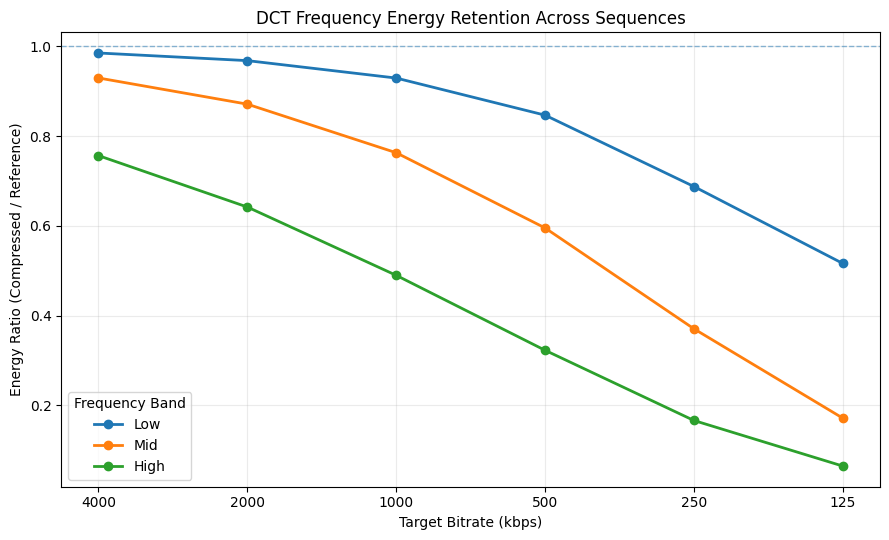

Saved: /kaggle/working/B1_results/B1_overall_DCT_energy_ratio.png
Sequences: 6


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/kaggle/working/B1_results")
df = pd.read_csv(OUT / "freqB1_bitrate.csv")

# DCT 요약 대역만 선택
dct = df[
    (df["transform"] == "DCT_summary") &
    (df["band"].isin(["Low", "Mid", "High"]))
]

# 시퀀스별 동일 가중치 평균
avg = (
    dct.groupby(["bitrate_kbps", "band"], as_index=False)
    ["energy_ratio"].mean()
)

fig, ax = plt.subplots(figsize=(9, 5.5))

for band in ["Low", "Mid", "High"]:
    data = avg[avg["band"] == band].sort_values("bitrate_kbps")

    ax.plot(
        data["bitrate_kbps"],
        data["energy_ratio"],
        marker="o",
        linewidth=2,
        markersize=6,
        label=band
    )

ax.set_xscale("log", base=2)
ax.invert_xaxis()
ax.set_xticks([125, 250, 500, 1000, 2000, 4000])
ax.set_xticklabels(["125", "250", "500", "1000", "2000", "4000"])

ax.set_xlabel("Target Bitrate (kbps)")
ax.set_ylabel("Energy Ratio (Compressed / Reference)")
ax.set_title("DCT Frequency Energy Retention Across Sequences")

ax.axhline(1.0, linestyle="--", linewidth=1, alpha=0.5)
ax.grid(alpha=0.25)
ax.legend(title="Frequency Band")

fig.tight_layout()

save_path = OUT / "B1_overall_DCT_energy_ratio.png"
fig.savefig(save_path, dpi=200, bbox_inches="tight")

plt.show()

print(f"Saved: {save_path}")
print(f"Sequences: {dct['sequence'].nunique()}")

## 사전실험 B-2 : 객체 크기별 ROI 주파수 변화 분석
### 작은 객체에서 특정 주파수 대역의 손실이 더 큰가?

In [4]:
import json
from pathlib import Path

p = Path("/kaggle/input/notebooks/naeunku/uvg-eval-yolo/gt_HighwayView_720p30.json")

with open(p, encoding="utf-8") as f:
    d = json.load(f)

print("최상위 키:", list(d.keys()))

for key in ["images", "annotations", "categories"]:
    if key in d:
        print(f"\n{key} 개수:", len(d[key]))
        print("첫 번째 항목:", d[key][0])

최상위 키: ['images', 'annotations', 'categories']

images 개수: 300
첫 번째 항목: {'id': 0, 'file_name': '000000.png', 'width': 1280, 'height': 720}

annotations 개수: 5557
첫 번째 항목: {'id': 1, 'image_id': 0, 'category_id': 3, 'bbox': [703.14, 286.97, 22.37, 18.47], 'area': 413.04, 'iscrowd': 0, 'track_id': 1}

categories 개수: 80
첫 번째 항목: {'id': 1, 'name': 'person'}


**객체 ROI가 작을 때 주파수 분석의 해상도가 제한된다**
- 객체 영역을 임의로 확대하지 않음
- DCT는 8×8 블록과 GT 영역의 겹침 비율로 가중
- Wavelet은 각 서브밴드 좌표에 ROI를 대응시키는 방식으로 구현

In [5]:

import json
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

# ============================================================
# 1. 설정
# ============================================================

ROOT = Path("/kaggle/input/notebooks/naeunku")
REF = ROOT / "uvg-build-dataset/uvg_cctv"
ENC = ROOT / "uvg-eval3-gop60/cctv_gop60"
GT = ROOT / "uvg-eval-yolo"

OUT = Path("/kaggle/working/B2_results")
OUT.mkdir(parents=True, exist_ok=True)

SEQUENCES = [
    "HighwayView",
    "CampusView",
    "JobFair",
    "VolleyballGame",
    "FloorballGame",
    "FloorballTrain"
]

RATES = [4000, 2000, 1000, 500, 250, 125]
FRAME_STEP = 5
EPS = 1e-12
SEED = 42

DCT_BANDS = {
    "DC": [0],
    "Low": [1, 2],
    "Mid": [3, 4, 5, 6],
    "High": list(range(7, 15))
}

WAVELET_BANDS = [
    "LL2", "LH2", "HL2", "HH2",
    "LH1", "HL1", "HH1"
]

# ============================================================
# 2. DCT 행렬 및 마스크 사전 계산
# ============================================================

def make_dct_matrix(n=8):
    k = np.arange(n)[:, None]
    x = np.arange(n)[None, :]

    T = np.cos(np.pi * (2*x + 1) * k / (2*n))
    T[0] *= np.sqrt(1/n)
    T[1:] *= np.sqrt(2/n)

    return T.astype(np.float32)


T = make_dct_matrix()

u, v = np.meshgrid(np.arange(8), np.arange(8))
diag = u + v

DCT_MASKS = {
    name: np.isin(diag, indices)
    for name, indices in DCT_BANDS.items()
}

# DCT 계산 정확도 검증
test = np.arange(64, dtype=np.float32).reshape(8, 8)
assert np.allclose(
    T @ test @ T.T,
    cv2.dct(test),
    atol=1e-4
)

print("DCT verification passed")

# ============================================================
# 3. 영상 디코딩
# ============================================================

def read_selected_frames(path, indices):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise FileNotFoundError(path)

    frames = {}
    selected = set(indices)
    last = max(indices)

    for idx in range(last + 1):
        ok, frame = cap.read()

        if not ok:
            cap.release()
            raise RuntimeError(
                f"Decode failed: {path}, frame={idx}"
            )

        if idx in selected:
            frames[idx] = cv2.cvtColor(
                frame, cv2.COLOR_BGR2YCrCb
            )[:, :, 0].astype(np.float32)

    cap.release()
    return frames


def get_frame_count(path):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise FileNotFoundError(path)

    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return n

# ============================================================
# 4. 벡터화 DCT
# ============================================================

def dct_all_blocks(y):
    h, w = y.shape

    if h % 8 or w % 8:
        raise ValueError("Image dimensions must be divisible by 8")

    blocks = (
        y.reshape(h//8, 8, w//8, 8)
         .transpose(0, 2, 1, 3)
    )

    return np.einsum(
        "au,ijuv,bv->ijab",
        T, blocks, T,
        optimize=True
    )


def wavelet_all(y):
    ll2, (lh2, hl2, hh2), (lh1, hl1, hh1) = (
        pywt.wavedec2(
            y, "haar",
            level=2,
            mode="periodization"
        )
    )

    return {
        "LL2": ll2,
        "LH2": lh2,
        "HL2": hl2,
        "HH2": hh2,
        "LH1": lh1,
        "HL1": hl1,
        "HH1": hh1
    }

# ============================================================
# 5. GT 및 ROI 사전 계산
# ============================================================

def size_group(area):
    if area < 1024:
        return "Small"
    if area < 9216:
        return "Medium"
    return "Large"


def clip_bbox(bbox, h, w):
    x, y, bw, bh = map(float, bbox)

    x1 = max(0.0, min(float(w), x))
    y1 = max(0.0, min(float(h), y))
    x2 = max(0.0, min(float(w), x + bw))
    y2 = max(0.0, min(float(h), y + bh))

    if x2 <= x1 or y2 <= y1:
        return None

    return x1, y1, x2, y2


def make_roi_weights(bbox, h, w):
    clipped = clip_bbox(bbox, h, w)

    if clipped is None:
        return None

    x1, y1, x2, y2 = clipped

    # ROI와 겹치는 8x8 DCT 블록만 선택
    bx1 = int(np.floor(x1 / 8))
    by1 = int(np.floor(y1 / 8))
    bx2 = int(np.ceil(x2 / 8))
    by2 = int(np.ceil(y2 / 8))

    bx = np.arange(bx1, bx2)
    by = np.arange(by1, by2)

    wx = np.maximum(
        0,
        np.minimum((bx + 1)*8, x2) -
        np.maximum(bx*8, x1)
    ) / 8

    wy = np.maximum(
        0,
        np.minimum((by + 1)*8, y2) -
        np.maximum(by*8, y1)
    ) / 8

    dct_weights = (
        wy[:, None] * wx[None, :]
    ).astype(np.float32)

    wavelet_regions = {}

    for scale in [2, 4]:
        sx1 = int(np.floor(x1 / scale))
        sy1 = int(np.floor(y1 / scale))
        sx2 = int(np.ceil(x2 / scale))
        sy2 = int(np.ceil(y2 / scale))

        sx = np.arange(sx1, sx2)
        sy = np.arange(sy1, sy2)

        swx = np.maximum(
            0,
            np.minimum((sx + 1)*scale, x2) -
            np.maximum(sx*scale, x1)
        ) / scale

        swy = np.maximum(
            0,
            np.minimum((sy + 1)*scale, y2) -
            np.maximum(sy*scale, y1)
        ) / scale

        wavelet_regions[scale] = (
            sy1, sy2, sx1, sx2,
            (swy[:, None] * swx[None, :]).astype(
                np.float32
            )
        )

    return {
        "dct": (by1, by2, bx1, bx2, dct_weights),
        "wavelet": wavelet_regions
    }


def prepare_frame_rois(anns, h, w, rng):
    occupancy = np.zeros((h, w), dtype=np.uint8)

    for ann in anns:
        clipped = clip_bbox(ann["bbox"], h, w)
        if clipped is None:
            continue

        x1, y1, x2, y2 = clipped

        occupancy[
            int(np.floor(y1)):int(np.ceil(y2)),
            int(np.floor(x1)):int(np.ceil(x2))
        ] = 1

    # 적분 영상으로 배경 후보 영역의 객체 포함 여부를
    # O(1)에 확인
    integral = cv2.integral(occupancy)

    rois = []

    for ann in anns:
        obj_weights = make_roi_weights(
            ann["bbox"], h, w
        )

        if obj_weights is None:
            continue

        meta = {
            "annotation_id": ann["id"],
            "category_id": ann["category_id"],
            "area": ann["area"],
            "size": size_group(ann["area"])
        }

        rois.append({
            **meta,
            "roi_type": "Object",
            "weights": obj_weights
        })

        _, _, bw, bh = ann["bbox"]
        bw = int(np.ceil(bw))
        bh = int(np.ceil(bh))

        if bw <= 0 or bh <= 0 or bw > w or bh > h:
            continue

        for _ in range(30):
            x = int(rng.integers(0, w-bw+1))
            y = int(rng.integers(0, h-bh+1))

            occupied = (
                integral[y+bh, x+bw]
                - integral[y, x+bw]
                - integral[y+bh, x]
                + integral[y, x]
            )

            if occupied == 0:
                bg_weights = make_roi_weights(
                    [x, y, bw, bh], h, w
                )

                rois.append({
                    **meta,
                    "roi_type": "Background",
                    "weights": bg_weights
                })
                break

    return rois

# ============================================================
# 6. ROI별 주파수 에너지 계산
# ============================================================

def weighted_energy(a, b, weights):
    a = a.astype(np.float64, copy=False)
    b = b.astype(np.float64, copy=False)

    ref_e = np.sum(weights * a*a)
    cmp_e = np.sum(weights * b*b)
    err_e = np.sum(weights * (a-b)**2)

    return float(ref_e), float(cmp_e), float(err_e)


def measure_roi(rd, cd, rw, cw, roi):
    result = []
    by1, by2, bx1, bx2, weights = roi["dct"]

    a = rd[by1:by2, bx1:bx2]
    b = cd[by1:by2, bx1:bx2]

    for band, mask in DCT_MASKS.items():
        aa = a[:, :, mask]
        bb = b[:, :, mask]

        er, ec, ee = weighted_energy(
            aa, bb, weights[:, :, None]
        )

        result.append((
            "DCT_summary", band, er, ec, ee
        ))

    for band in WAVELET_BANDS:
        scale = 4 if band.endswith("2") else 2

        y1, y2, x1, x2, wt = roi["wavelet"][scale]

        aa = rw[band][y1:y2, x1:x2]
        bb = cw[band][y1:y2, x1:x2]

        er, ec, ee = weighted_energy(aa, bb, wt)

        result.append((
            "Wavelet", band, er, ec, ee
        ))

    return result

# ============================================================
# 7. 전체 실험
# ============================================================

def run_b2():
    records = []
    rng = np.random.default_rng(SEED)

    for seq in SEQUENCES:
        gt_path = GT / f"gt_{seq}_720p30.json"
        ref_path = REF / seq / "ref_720p30.mkv"

        with open(gt_path, encoding="utf-8") as f:
            gt = json.load(f)

        image_to_frame = {
            img["id"]: int(Path(img["file_name"]).stem)
            for img in gt["images"]
        }

        frame_anns = defaultdict(list)

        for ann in gt["annotations"]:
            if ann.get("iscrowd", 0):
                continue

            idx = image_to_frame[ann["image_id"]]
            frame_anns[idx].append(ann)

        n_frames = get_frame_count(ref_path)

        indices = [
            idx for idx in range(0, n_frames, FRAME_STEP)
            if idx in frame_anns
        ]

        # GT와 배경 ROI를 비트레이트별로 재계산하지 않음
        prepared_rois = {
            idx: prepare_frame_rois(
                frame_anns[idx], 720, 1280, rng
            )
            for idx in indices
        }

        ref_frames = read_selected_frames(
            ref_path, indices
        )

        # 원본 주파수 변환도 1회만 수행
        ref_freq = {
            idx: (
                dct_all_blocks(ref_frames[idx]),
                wavelet_all(ref_frames[idx])
            )
            for idx in indices
        }

        print(
            f"\n[{seq}] "
            f"frames={len(indices)}, "
            f"ROIs={sum(map(len, prepared_rois.values()))}"
        )

        for rate in RATES:
            path = ENC / seq / f"cctv_{rate}k.mp4"

            if not path.exists():
                print(f"  SKIP {rate} kbps")
                continue

            cmp_frames = read_selected_frames(
                path, indices
            )

            for idx in indices:
                rd, rw = ref_freq[idx]

                cd = dct_all_blocks(cmp_frames[idx])
                cw = wavelet_all(cmp_frames[idx])

                for roi in prepared_rois[idx]:
                    measurements = measure_roi(
                        rd, cd, rw, cw, roi["weights"]
                    )

                    for transform, band, er, ec, ee in measurements:
                        records.append({
                            "sequence": seq,
                            "bitrate_kbps": rate,
                            "frame": idx,
                            "annotation_id": roi["annotation_id"],
                            "category_id": roi["category_id"],
                            "area": roi["area"],
                            "size": roi["size"],
                            "roi_type": roi["roi_type"],
                            "transform": transform,
                            "band": band,
                            "ref_energy": er,
                            "cmp_energy": ec,
                            "error_energy": ee,
                            "energy_ratio": (
                                ec/er if er > EPS else np.nan
                            ),
                            "normalized_error": (
                                ee/er if er > EPS else np.nan
                            )
                        })

            print(f"  {rate} kbps done")

        # 시퀀스별 메모리 해제
        del ref_frames, ref_freq, prepared_rois

    df = pd.DataFrame(records)

    raw_path = OUT / "B2_roi_raw.csv"
    df.to_csv(raw_path, index=False)

    keys = [
        "sequence", "bitrate_kbps", "size",
        "roi_type", "transform", "band"
    ]

    agg = (
        df.groupby(keys, as_index=False)[
            ["ref_energy", "cmp_energy", "error_energy"]
        ].sum()
    )

    agg["energy_ratio"] = (
        agg["cmp_energy"] /
        agg["ref_energy"].replace(0, np.nan)
    )

    agg["normalized_error"] = (
        agg["error_energy"] /
        agg["ref_energy"].replace(0, np.nan)
    )

    agg.to_csv(
        OUT / "B2_roi_summary.csv",
        index=False
    )

    # --------------------------------------------------------
    # 8. 그래프
    # --------------------------------------------------------

    dct = agg[
        (agg["roi_type"] == "Object") &
        (agg["transform"] == "DCT_summary")
    ]

    for band in ["Low", "Mid", "High"]:
        subset = dct[dct["band"] == band]

        avg = (
            subset.groupby(
                ["bitrate_kbps", "size"], as_index=False
            )["normalized_error"].mean()
        )

        fig, ax = plt.subplots(figsize=(8, 5))

        for size in ["Small", "Medium", "Large"]:
            s = avg[avg["size"] == size].sort_values(
                "bitrate_kbps"
            )

            if not s.empty:
                ax.plot(
                    s["bitrate_kbps"],
                    s["normalized_error"],
                    marker="o",
                    label=size
                )

        ax.set_xscale("log", base=2)
        ax.invert_xaxis()
        ax.set_xlabel("Target Bitrate (kbps)")
        ax.set_ylabel("Normalized Coefficient Error")
        ax.set_title(f"B-2 Object ROI | DCT {band}")
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()

        fig.savefig(
            OUT / f"B2_DCT_{band}_size.png",
            dpi=180
        )
        plt.close(fig)

    print("\nB-2 completed")
    print("Raw rows:", len(df))
    print("Summary rows:", len(agg))
    print("Saved to:", OUT)

    return df, agg


b2_raw, b2_summary = run_b2()


DCT verification passed

[HighwayView] frames=60, ROIs=2231
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

[CampusView] frames=60, ROIs=2604
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

[JobFair] frames=60, ROIs=4648
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

[VolleyballGame] frames=60, ROIs=2136
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

[FloorballGame] frames=42, ROIs=578
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

[FloorballTrain] frames=60, ROIs=2701
  4000 kbps done
  2000 kbps done
  1000 kbps done
  500 kbps done
  250 kbps done
  125 kbps done

B-2 completed
Raw rows: 983268
Summary rows: 2376
Saved to: /kaggle/working/B2_results


In [6]:
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
B-2: /kaggle/working/B2_results/B2_roi_raw.csv
Weights: /kaggle/input/notebooks/naeunku/uvg-eval3-gop60/yolo26s.pt

[HighwayView] 60 sampled frames
  4000 kbps | 1.0s
  2000 kbps | 0.9s
  1000 kbps | 0.8s
   500 kbps | 0.8s
   250 kbps | 0.8s
   125 kbps | 0.7s

[CampusView] 60 sampled frames
  4000 kbps | 1.1s
  2000 kbps | 1.0s
  1000 kbps | 0.9s
   500 kbps | 0.8s
   250 kbps | 0.8s
   125 kbps | 0.7s

[JobFair] 60 sampled frames
  4000 kbps | 1.1s
  2000 kbps | 0.9s
  1000 kbps | 0.9s
   500 kbps | 0.8s
   250 kbps | 0.8s
   125 kbps | 0.7s

[VolleyballGame] 60 sampled frames
  4000 kbps | 1.1s
  2000 kbps | 0.9s
  1000 kbps | 0.8s
   500 kbps | 0.8s
   250 kbps | 0.8s
   125 kbps 

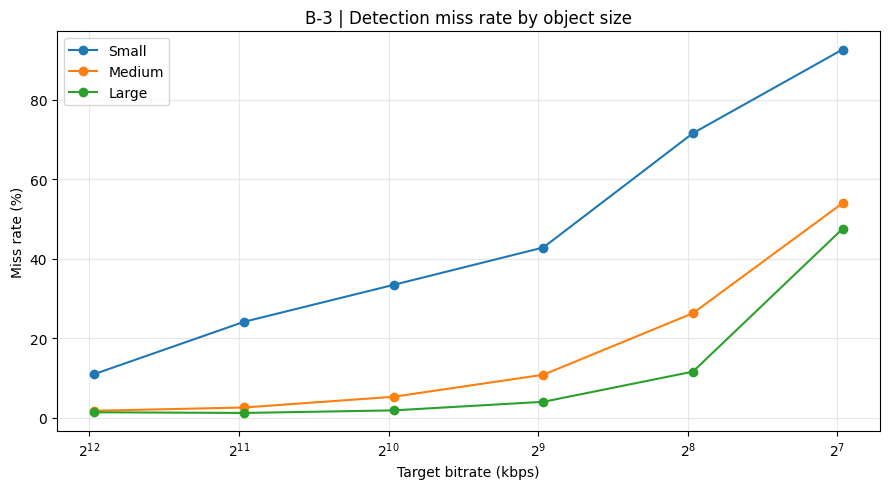

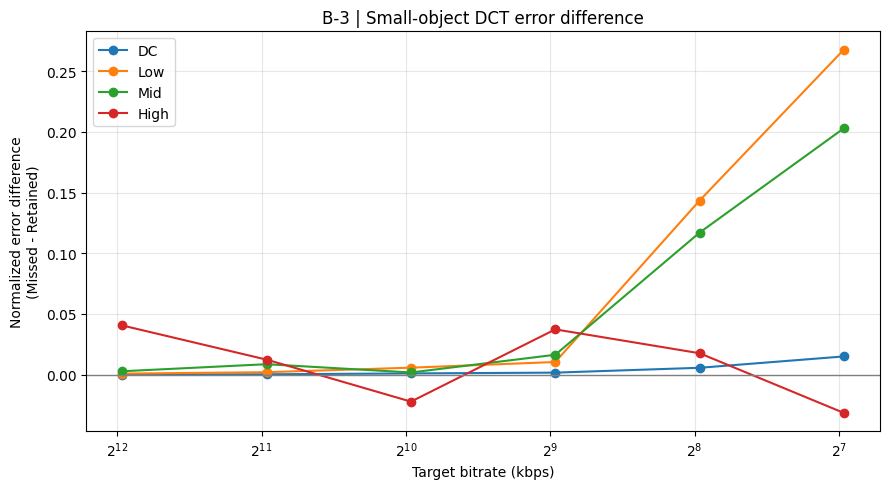


========== B-3 SUMMARY ==========
Sequences: 6
Bitrates: [np.int64(125), np.int64(250), np.int64(500), np.int64(1000), np.int64(2000), np.int64(4000)]
Confidence thresholds: [0.25, 0.1]
Detection records: 46062
Frequency rows: 506682
B-2 object coverage: 100.00%

Output files:
 - B3_detection_status.csv
 - B3_frequency_comparison.csv
 - B3_frequency_detection_merged.csv
 - B3_miss_rate.csv
 - B3_miss_rate.png
 - B3_small_DCT_error_difference.png
 - B3_within_stratum_difference.csv


In [7]:

# ============================================================
# B-3 | Compression frequency change vs detection failure
# A-3 GOP60 settings + actual B-2 CSV schema
# ============================================================

import json
import time
import zipfile
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ============================================================
# 1. CONFIG
# ============================================================

ROOT = Path("/kaggle/input/notebooks/naeunku")
REF_ROOT = ROOT / "uvg-build-dataset/uvg_cctv"
ENC_ROOT = ROOT / "uvg-eval3-gop60/cctv_gop60"
GT_ROOT = ROOT / "uvg-eval-yolo"

OUT = Path("/kaggle/working/B3_results")
OUT.mkdir(parents=True, exist_ok=True)

SEQS = [
    "HighwayView",
    "CampusView",
    "JobFair",
    "VolleyballGame",
    "FloorballGame",
    "FloorballTrain"
]
RATES = [4000, 2000, 1000, 500, 250, 125]

FRAME_STEP = 5
BATCH = 16
IMGSZ = 640
PRED_CONF = 0.001
MAX_DET = 300

# Object-level analysis thresholds
MATCH_IOU = 0.5
MATCH_CONFS = [0.25, 0.10]

KEYS = [
    "sequence", "frame", "annotation_id", "bitrate_kbps"
]

assert torch.cuda.is_available(), "Kaggle GPU를 켜야 해."
print("GPU:", torch.cuda.get_device_name(0))

torch.backends.cudnn.benchmark = True

# ============================================================
# 2. FIND INPUT FILES
# ============================================================

def find_one(root, filename):
    matches = list(root.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"{filename} not found under {root}"
        )
    return matches[0]


def get_b2_csv():
    candidates = [
        Path("/kaggle/working/B2_results/B2_roi_raw.csv"),
        Path("/kaggle/input/B2_results/B2_roi_raw.csv"),
    ]

    for p in candidates:
        if p.exists():
            return p

    # Kaggle Input에서 파일 검색
    matches = list(
        Path("/kaggle/input").rglob("B2_roi_raw.csv")
    )
    if matches:
        return matches[0]

    # ZIP 형태로 업로드한 경우
    zips = (
        list(Path("/kaggle/input").rglob("B2_results.zip"))
        + list(Path("/kaggle/working").rglob("B2_results.zip"))
    )

    for zp in zips:
        with zipfile.ZipFile(zp) as z:
            members = [
                n for n in z.namelist()
                if Path(n).name == "B2_roi_raw.csv"
            ]
            if members:
                dest = OUT / "B2_roi_raw.csv"
                with z.open(members[0]) as src:
                    import shutil
                    with open(dest, "wb") as dst:
                        shutil.copyfileobj(src, dst)
                return dest

    raise FileNotFoundError(
        "B2_roi_raw.csv 또는 B2_results.zip을 찾지 못했어."
    )


B2_CSV = get_b2_csv()
WEIGHTS = find_one(ROOT, "yolo26s.pt")

print("B-2:", B2_CSV)
print("Weights:", WEIGHTS)

model = YOLO(str(WEIGHTS))

# ============================================================
# 3. LOAD GT
# ============================================================

def load_gt(seq):
    path = GT_ROOT / f"gt_{seq}_720p30.json"

    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    frame_map = {
        im["id"]: int(Path(im["file_name"]).stem)
        for im in data["images"]
    }

    frames = sorted({
        f for f in frame_map.values()
        if f % FRAME_STEP == 0
    })

    gt_by_frame = defaultdict(list)

    for ann in data["annotations"]:
        if ann.get("iscrowd", 0):
            continue

        frame = frame_map[ann["image_id"]]
        if frame % FRAME_STEP != 0:
            continue

        x, y, w, h = ann["bbox"]
        if w <= 0 or h <= 0:
            continue

        area = float(ann.get("area", w*h))

        gt_by_frame[frame].append({
            "annotation_id": int(ann["id"]),
            "category_id": int(ann["category_id"]),
            "bbox": [x, y, x+w, y+h],
            "area": area,
            "size": (
                "Small" if area < 1024 else
                "Medium" if area < 9216 else "Large"
            )
        })

    return gt_by_frame, frames

# ============================================================
# 4. GPU BATCH INFERENCE
# ============================================================

@torch.inference_mode()
def infer_video(video_path, frame_ids):
    """
    Sequential video decoding + GPU batch inference.
    A-3 predict settings retained.
    """
    video_path = Path(video_path)

    if not video_path.exists():
        raise FileNotFoundError(video_path)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {video_path}")

    target = set(frame_ids)
    output = {}
    batch_frames = []
    batch_ids = []

    def flush():
        if not batch_frames:
            return

        # NMS IoU intentionally omitted, as in A-3
        results = model.predict(
            source=batch_frames,
            imgsz=IMGSZ,
            conf=PRED_CONF,
            max_det=MAX_DET,
            device=0,
            verbose=False
        )

        for fid, result in zip(batch_ids, results):
            b = result.boxes

            output[fid] = {
                "boxes": (
                    b.xyxy.cpu().numpy().astype(np.float32)
                ),
                "scores": (
                    b.conf.cpu().numpy().astype(np.float32)
                ),
                # A-3 GT convention
                "classes": (
                    b.cls.cpu().numpy().astype(np.int32) + 1
                )
            }

        batch_frames.clear()
        batch_ids.clear()

    last = max(frame_ids)

    for idx in range(last + 1):
        ok, frame = cap.read()
        if not ok:
            break

        if idx not in target:
            continue

        batch_frames.append(frame)
        batch_ids.append(idx)

        if len(batch_frames) == BATCH:
            flush()

    flush()
    cap.release()

    missing = target - set(output)

    if missing:
        raise RuntimeError(
            f"{video_path.name}: missing frames "
            f"{sorted(missing)[:10]}"
        )

    return output

# ============================================================
# 5. MATCHING: IoU + CLASS + CONFIDENCE
# ============================================================

def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros(
            (len(a), len(b)),
            dtype=np.float32
        )

    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])

    wh = np.maximum(rb-lt, 0)
    inter = wh[..., 0] * wh[..., 1]

    area_a = np.prod(
        np.maximum(a[:, 2:] - a[:, :2], 0),
        axis=1
    )
    area_b = np.prod(
        np.maximum(b[:, 2:] - b[:, :2], 0),
        axis=1
    )

    union = area_a[:, None] + area_b[None, :] - inter

    return inter / np.maximum(union, 1e-9)


def match_gt(objects, pred, conf_threshold):
    """
    One-to-one matching, confidence-first greedy.
    Returns bool per GT object.
    """
    n = len(objects)
    detected = np.zeros(n, dtype=bool)

    if n == 0:
        return detected

    keep = pred["scores"] >= conf_threshold

    boxes = pred["boxes"][keep]
    scores = pred["scores"][keep]
    classes = pred["classes"][keep]

    if len(boxes) == 0:
        return detected

    gt_boxes = np.array(
        [o["bbox"] for o in objects],
        dtype=np.float32
    )
    gt_classes = np.array(
        [o["category_id"] for o in objects],
        dtype=np.int32
    )

    ious = iou_matrix(gt_boxes, boxes)

    valid = (
        (ious >= MATCH_IOU) &
        (gt_classes[:, None] == classes[None, :])
    )

    used_gt = np.zeros(n, dtype=bool)

    for p in np.argsort(-scores):
        candidates = np.where(
            valid[:, p] & ~used_gt
        )[0]

        if len(candidates) == 0:
            continue

        best = candidates[
            np.argmax(ious[candidates, p])
        ]

        detected[best] = True
        used_gt[best] = True

    return detected

# ============================================================
# 6. DETECTION EXPERIMENT
# ============================================================

def run_detection():
    rows = []
    t0 = time.time()

    for seq in SEQS:
        gt_by_frame, frames = load_gt(seq)

        print(
            f"\n[{seq}] {len(frames)} sampled frames",
            flush=True
        )

        # Reference: once per sequence
        ref_path = REF_ROOT / seq / "ref_720p30.mkv"
        ref_preds = infer_video(ref_path, frames)

        ref_matches = {}

        for fid in frames:
            objs = gt_by_frame[fid]
            ref_matches[fid] = {
                conf: match_gt(objs, ref_preds[fid], conf)
                for conf in MATCH_CONFS
            }

        del ref_preds

        for rate in RATES:
            t = time.time()

            video = (
                ENC_ROOT / seq / f"cctv_{rate}k.mp4"
            )
            cmp_preds = infer_video(video, frames)

            for fid in frames:
                objs = gt_by_frame[fid]

                for conf in MATCH_CONFS:
                    ref_flags = ref_matches[fid][conf]

                    cmp_flags = match_gt(
                        objs, cmp_preds[fid], conf
                    )

                    for idx, obj in enumerate(objs):
                        # Exclude GT not detected in reference
                        if not ref_flags[idx]:
                            continue

                        rows.append({
                            "sequence": seq,
                            "frame": fid,
                            "annotation_id": obj["annotation_id"],
                            "category_id": obj["category_id"],
                            "bitrate_kbps": rate,
                            "area": obj["area"],
                            "size": obj["size"],
                            "match_conf": conf,
                            "compressed_detected": int(
                                cmp_flags[idx]
                            ),
                            "missed": int(not cmp_flags[idx])
                        })

            del cmp_preds

            print(
                f"  {rate:4d} kbps "
                f"| {time.time()-t:.1f}s",
                flush=True
            )

    result = pd.DataFrame(rows)

    result.to_csv(
        OUT / "B3_detection_status.csv",
        index=False
    )

    print(
        f"\nDetection finished in "
        f"{time.time()-t0:.1f}s"
    )

    return result


detection = run_detection()

# ============================================================
# 7. LOAD ACTUAL B-2 RESULTS
# ============================================================

B2_COLS = [
    "sequence",
    "bitrate_kbps",
    "frame",
    "annotation_id",
    "category_id",
    "area",
    "size",
    "roi_type",
    "transform",
    "band",
    "ref_energy",
    "cmp_energy",
    "error_energy",
    "energy_ratio",
    "normalized_error"
]

b2 = pd.read_csv(
    B2_CSV,
    usecols=B2_COLS
)

# Only GT object ROIs, not matched backgrounds
b2 = b2[
    b2["roi_type"] == "Object"
].copy()

print("\nB-2 object rows:", len(b2))
print(
    "B-2 frequency bands:",
    b2.groupby("transform")["band"].unique().to_dict()
)

# ============================================================
# 8. VALIDATE AND MERGE
# ============================================================

FREQ_KEYS = KEYS + ["transform", "band"]

# B-2 frequency measurement uniqueness
assert not b2.duplicated(FREQ_KEYS).any(), (
    "B-2 contains duplicate frequency measurements"
)

# Detection uniqueness includes confidence threshold
assert not detection.duplicated(
    KEYS + ["match_conf"]
).any(), "Duplicate B-3 detection records"

# Compare unique object identities, not raw row counts
b2_objects = b2[KEYS].drop_duplicates()

det_objects = detection[KEYS].drop_duplicates()

coverage_check = det_objects.merge(
    b2_objects,
    on=KEYS,
    how="left",
    indicator=True
)

coverage = coverage_check["_merge"].eq("both").mean()

print(f"\nB-2 object match coverage: {coverage:.2%}")

if coverage < 1.0:
    missing = coverage_check[
        coverage_check["_merge"] != "both"
    ]

    missing.to_csv(
        OUT / "B3_unmatched_objects.csv",
        index=False
    )

    raise RuntimeError(
        f"B-2 object keys missing: {len(missing)}. "
        "Check GT annotation IDs and frame sampling."
    )

# Every B-2 object should have 11 bands:
# DCT_summary: DC, Low, Mid, High
# Wavelet: LL2, LH2, HL2, HH2, LH1, HL1, HH1

band_counts = (
    b2.groupby(KEYS, sort=False)
    .size()
)

if not band_counts.eq(11).all():
    raise RuntimeError(
        "Some B-2 objects do not have exactly 11 bands."
    )

# Avoid duplicate metadata after merge
freq = b2[
    KEYS + [
        "transform", "band",
        "ref_energy", "cmp_energy",
        "error_energy",
        "energy_ratio", "normalized_error"
    ]
]

merged = detection.merge(
    freq,
    on=KEYS,
    how="left",
    validate="many_to_many"
)

# Each detection record must have 11 frequency rows
expected_rows = len(detection) * 11

assert len(merged) == expected_rows, (
    f"Merge row mismatch: "
    f"{len(merged)} vs {expected_rows}"
)

assert merged["transform"].notna().all()

merged.to_csv(
    OUT / "B3_frequency_detection_merged.csv",
    index=False
)

print("Detection records:", len(detection))
print("Merged frequency rows:", len(merged))

# ============================================================
# 9. MISS RATE
# ============================================================

miss_rate = (
    detection.groupby(
        [
            "sequence",
            "bitrate_kbps",
            "size",
            "match_conf"
        ],
        as_index=False
    )
    .agg(
        n_objects=("missed", "size"),
        n_missed=("missed", "sum"),
        miss_rate=("missed", "mean")
    )
)

miss_rate.to_csv(
    OUT / "B3_miss_rate.csv",
    index=False
)

# ============================================================
# 10. FREQUENCY COMPARISON
# ============================================================

# Compare missed vs retained at matched bitrate/size/sequence
group_cols = [
    "sequence",
    "bitrate_kbps",
    "size",
    "match_conf",
    "transform",
    "band",
    "missed"
]

freq_summary = (
    merged.groupby(
        group_cols,
        as_index=False
    )
    .agg(
        n_objects=("annotation_id", "size"),
        energy_ratio_mean=("energy_ratio", "mean"),
        energy_ratio_median=("energy_ratio", "median"),
        normalized_error_mean=("normalized_error", "mean"),
        normalized_error_median=("normalized_error", "median")
    )
)

freq_summary.to_csv(
    OUT / "B3_frequency_comparison.csv",
    index=False
)

# Within-stratum difference: Missed minus Retained
index_cols = [
    "sequence",
    "bitrate_kbps",
    "size",
    "match_conf",
    "transform",
    "band"
]

wide = freq_summary.pivot(
    index=index_cols,
    columns="missed",
    values=[
        "n_objects",
        "energy_ratio_mean",
        "normalized_error_mean"
    ]
)

wide.columns = [
    f"{metric}_{'missed' if missed == 1 else 'retained'}"
    for metric, missed in wide.columns
]

wide = wide.reset_index()

required = [
    "normalized_error_mean_missed",
    "normalized_error_mean_retained"
]

wide = wide.dropna(subset=required).copy()

wide["error_difference"] = (
    wide["normalized_error_mean_missed"]
    - wide["normalized_error_mean_retained"]
)

wide["energy_ratio_difference"] = (
    wide["energy_ratio_mean_missed"]
    - wide["energy_ratio_mean_retained"]
)

wide.to_csv(
    OUT / "B3_within_stratum_difference.csv",
    index=False
)

# ============================================================
# 11. PLOTS
# ============================================================

primary_conf = 0.25

# Plot 1: Detection miss rate
plot_miss = (
    miss_rate[
        miss_rate["match_conf"] == primary_conf
    ]
    .groupby(
        ["bitrate_kbps", "size"],
        as_index=False
    )["miss_rate"].mean()
)

fig, ax = plt.subplots(figsize=(9, 5))

for size in ["Small", "Medium", "Large"]:
    p = plot_miss[
        plot_miss["size"] == size
    ].sort_values("bitrate_kbps")

    if len(p):
        ax.plot(
            p["bitrate_kbps"],
            p["miss_rate"] * 100,
            marker="o",
            label=size
        )

ax.set_xscale("log", base=2)
ax.invert_xaxis()
ax.set_xlabel("Target bitrate (kbps)")
ax.set_ylabel("Miss rate (%)")
ax.set_title(
    "B-3 | Detection miss rate by object size"
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "B3_miss_rate.png",
    dpi=200
)
plt.show()

# Plot 2: DCT band difference, Small objects
plot_diff = wide[
    (wide["match_conf"] == primary_conf)
    & (wide["size"] == "Small")
    & (wide["transform"] == "DCT_summary")
]

plot_diff = (
    plot_diff.groupby(
        ["bitrate_kbps", "band"],
        as_index=False
    )["error_difference"].mean()
)

fig, ax = plt.subplots(figsize=(9, 5))

for band in ["DC", "Low", "Mid", "High"]:
    p = plot_diff[
        plot_diff["band"] == band
    ].sort_values("bitrate_kbps")

    if len(p):
        ax.plot(
            p["bitrate_kbps"],
            p["error_difference"],
            marker="o",
            label=band
        )

ax.axhline(0, color="gray", linewidth=1)
ax.set_xscale("log", base=2)
ax.invert_xaxis()
ax.set_xlabel("Target bitrate (kbps)")
ax.set_ylabel(
    "Normalized error difference\n"
    "(Missed - Retained)"
)
ax.set_title(
    "B-3 | Small-object DCT error difference"
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "B3_small_DCT_error_difference.png",
    dpi=200
)
plt.show()

# ============================================================
# 12. FINAL CHECK
# ============================================================

print("\n========== B-3 SUMMARY ==========")
print("Sequences:", detection["sequence"].nunique())
print("Bitrates:", sorted(detection["bitrate_kbps"].unique()))
print("Confidence thresholds:", MATCH_CONFS)
print("Detection records:", len(detection))
print("Frequency rows:", len(merged))
print("B-2 object coverage:", f"{coverage:.2%}")

print("\nOutput files:")
for p in sorted(OUT.iterdir()):
    print(" -", p.name)
